In [1]:
from __future__ import annotations

import math
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

In [2]:
DATA_DIR_NAMES = [
    'upcoding_v28_top10_ha2025_export',
]
DATA_ZIP_NAMES = [f'{name}.zip' for name in DATA_DIR_NAMES]
COEFF_NAME = 'cms_v28_cna_coefficients_export_features.csv'
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)

outputs_dir = Path("outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)
OUT = outputs_dir / 'supp_signal_vs_manipulability_outputs'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [3]:
TAU = 0.5
RHO = 0.5
RELATED_SCORE = 0.5
SIGNAL_MODERATION = 0.25
FLOOR = 0.03
ETA = 1e-6
VERSION = 'v4'
LAMBDAS = np.array([1e-6, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0])
K_PATH = [5, 10, 15, 20, 25, 30]

SIGNAL_MODERATED = ['hcc155', 'hcc280', 'hcc38', 'hcc93', 'hcc328', 'hcc226']
RELATED_EXTRA = ['hcc21', 'hcc23', 'hcc35', 'hcc62', 'hcc64', 'hcc264', 'hcc267', 'hcc327']
MANUAL_BLOCKS = [
    ('Diabetes model branch', ['hcc36', 'hcc37', 'hcc38']),
    ('Heart failure model branch', ['hcc224', 'hcc225', 'hcc226']),
    ('CKD model branch', ['hcc328', 'hcc329']),
    ('Substance-use model branch', ['hcc137', 'hcc138', 'hcc139']),
    ('Mental-health model branch', ['hcc151', 'hcc152', 'hcc153', 'hcc154', 'hcc155']),
    ('Vascular disease model branch', ['hcc263', 'hcc264', 'hcc267']),
    ('Cancer model branch', ['hcc20', 'hcc21', 'hcc22', 'hcc23']),
]


In [4]:
# Helper functions
def resolve_data_dir() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        for name in DATA_DIR_NAMES:
            candidate = root / name
            searched.append(str(candidate))
            if (candidate / 'baseline_hier.csv').exists():
                return candidate
    for root in SEARCH_ROOTS:
        for name in DATA_ZIP_NAMES:
            zip_path = root / name
            searched.append(str(zip_path))
            if zip_path.exists():
                work = OUT / '_unzipped'
                if work.exists():
                    shutil.rmtree(work)
                work.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(zip_path) as z:
                    z.extractall(work)
                for candidate in work.rglob('baseline_hier.csv'):
                    return candidate.parent
    raise FileNotFoundError(
        'Could not find the upcoding export folder or zip. Searched: ' + ', '.join(searched)
    )

def resolve_coeff_path() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        candidate = root / COEFF_NAME
        searched.append(str(candidate))
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        'Could not find the coefficient CSV. Searched: ' + ', '.join(searched)
    )


def parse_group_hccs(s) -> list[str]:
    if pd.isna(s):
        return []
    s = str(s).replace('HCC', 'hcc').replace(' ', '')
    return [p for p in s.split(',') if p.startswith('hcc')]


def get_target_rows(target_map: pd.DataFrame, features_all: list[str], coeff: pd.DataFrame) -> pd.DataFrame:
    rows = []
    if {'diagnosis_group', 'health_affairs_group_hccs', 'removal_effect_percent'}.issubset(target_map.columns):
        raw = target_map['removal_effect_percent'].astype(float).to_numpy()
        denom = float(np.nanmax(raw)) if np.nanmax(raw) > 0 else 1.0
        for _, r in target_map.iterrows():
            members = parse_group_hccs(r.get('health_affairs_group_hccs', ''))
            if not members:
                members = [str(r.get('target_hcc', r.get('hcc', '')))]
            rows.append({
                'diagnosis_group': str(r['diagnosis_group']),
                'members': members,
                'target_hcc': str(r.get('target_hcc', members[0] if members else '')),
                'score_raw': float(r['removal_effect_percent']),
                'score': float(r['removal_effect_percent']) / denom,
                'source': 'health-affairs-risk-contribution',
            })
        return pd.DataFrame(rows)
    if {'v22_label', 'hcc', 'ma_prev', 'tm_prev'}.issubset(target_map.columns):
        tmp = target_map.copy()
        tmp['lift_weight'] = tmp.get('lift_weight', 1.0)
        raw_scores = []
        for _, r in tmp.iterrows():
            h = str(r['hcc'])
            coef = float(coeff.loc[h, 'cna_coef']) if h in coeff.index else 1.0
            raw_scores.append(max(float(r['ma_prev']) - float(r['tm_prev']), 0.0) * float(r['lift_weight']) * abs(coef))
        denom = max(raw_scores) if max(raw_scores) > 0 else 1.0
        for raw, (_, r) in zip(raw_scores, tmp.iterrows()):
            h = str(r['hcc'])
            rows.append({
                'diagnosis_group': str(r['v22_label']),
                'members': [h],
                'target_hcc': h,
                'score_raw': raw,
                'score': raw / denom,
                'source': 'ma-tm-prevalence-lift-times-signal',
            })
        return pd.DataFrame(rows)
    raise ValueError('Unrecognized target mapping table format.')


def support_to_string(features: list[str], support) -> str:
    return '|'.join(features[i] for i in sorted(support))


def parse_support(s: object) -> set[str]:
    if pd.isna(s):
        return set()
    if isinstance(s, str):
        return {x for x in s.split('|') if x}
    return set(s)


In [5]:
class CaseStudyProblem:
    def __init__(self, data_dir: Path, coeff_path: Path):
        self.data_dir = data_dir
        self.base = pd.read_csv(data_dir / 'baseline_hier.csv')
        self.target_map = pd.read_csv(data_dir / 'target_mapping_table.csv')
        self.coeff = pd.read_csv(resolve_coeff_path()).set_index('feature')
        self.features_all = [c for c in self.base.columns if c != 'person_id']

        X_all_raw = self.base[self.features_all].astype(float).values
        self.prev_all = X_all_raw.mean(axis=0)
        self.active_idx = np.where(self.prev_all > 0)[0]
        self.features = [self.features_all[i] for i in self.active_idx]
        self.d = len(self.features)

        theta_all = np.zeros(len(self.features_all))
        self.desc_map = {f: '' for f in self.features_all}
        for i, f in enumerate(self.features_all):
            if f in self.coeff.index:
                theta_all[i] = float(self.coeff.loc[f, 'cna_coef'])
                self.desc_map[f] = str(self.coeff.loc[f, 'description'])
        self.theta = theta_all[self.active_idx]

        X = X_all_raw[:, self.active_idx]
        self.X_centered = X - X.mean(axis=0)
        self.Sigma = (self.X_centered.T @ self.X_centered) / self.X_centered.shape[0]
        self.Sigma = (self.Sigma + self.Sigma.T) / 2
        self.bvec = self.Sigma @ self.theta
        signal = self.X_centered @ self.theta
        self.sigma2 = float(0.25 * np.var(signal))
        self._support_risk_cache = {}
        self.build_cost_matrix()

    def build_cost_matrix(self):
        target_rows = get_target_rows(self.target_map, self.features_all, self.coeff)
        D_raw_all = np.full(len(self.features_all), FLOOR)
        group_blocks = []
        self.top_members = set()
        self.top_group = {}
        self.top_score = {}

        for _, row in target_rows.iterrows():
            score = float(row['score'])
            members = [m for m in row['members'] if isinstance(m, str) and m in self.features_all]
            group_name = str(row['diagnosis_group'])
            if members:
                group_blocks.append((group_name, members))
            for f in members:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + score)
                self.top_members.add(f)
                self.top_group[f] = group_name
                self.top_score[f] = score

        for f in RELATED_EXTRA:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + RELATED_SCORE)

        D_final_all = D_raw_all.copy()
        for f in SIGNAL_MODERATED:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_final_all[j] = FLOOR + SIGNAL_MODERATION * (D_final_all[j] - FLOOR)

        block_defs = group_blocks + MANUAL_BLOCKS
        seen, block_defs_unique = set(), []
        for name, members in block_defs:
            key = tuple(sorted(members))
            if key in seen:
                continue
            seen.add(key)
            block_defs_unique.append((name, members))

        B_all = np.zeros((len(self.features_all), len(self.features_all)))
        for _, members in block_defs_unique:
            idx = [self.features_all.index(f) for f in members if f in self.features_all]
            if len(idx) >= 2:
                v = np.zeros(len(self.features_all))
                for j in idx:
                    v[j] = math.sqrt(max(D_final_all[j], FLOOR))
                B_all += np.outer(v, v)

        self.D_all = D_final_all
        self.B_all = B_all
        self.D = D_final_all[self.active_idx]
        self.B = B_all[np.ix_(self.active_idx, self.active_idx)]
        if np.max(np.diag(self.B)) > 0:
            self.B = self.B / np.max(np.diag(self.B))
        self.G = TAU * (np.diag(self.D) + RHO * self.B) + ETA * np.eye(self.d)
        self.H = np.linalg.inv(self.G)

        comp_rows = []
        for pos, f in enumerate(self.features):
            j = self.features_all.index(f)
            comp_rows.append({
                'feature': f,
                'description': self.desc_map.get(f, ''),
                'baseline_prevalence': float(self.prev_all[j]),
                'theta_star': float(self.theta[pos]),
                'abs_theta_star': abs(float(self.theta[pos])),
                'top10_group': self.top_group.get(f, ''),
                'coding_sensitive': f in self.top_members,
                'group_score': float(self.top_score.get(f, np.nan)) if f in self.top_score else np.nan,
                'Hinv_diag': float(self.G[pos, pos]),
                'signal_moderated': f in SIGNAL_MODERATED,
                'active': True,
            })
        self.component_df = pd.DataFrame(comp_rows)

    def support_beta(self, S, lam: float):
        beta = np.zeros(self.d)
        idx = np.array(sorted(set(S)), dtype=int)
        if len(idx) == 0:
            return beta
        A = self.Sigma[np.ix_(idx, idx)] + lam * np.eye(len(idx))
        rhs = self.Sigma[np.ix_(idx, np.arange(self.d))] @ self.theta
        beta[idx] = np.linalg.solve(A + 1e-10 * np.eye(len(idx)), rhs)
        return beta

    def support_mask(self, S) -> int:
        mask = 0
        for i in sorted(set(S)):
            mask |= 1 << int(i)
        return mask

    def support_from_mask(self, mask: int) -> tuple[int, ...]:
        return tuple(i for i in range(self.d) if mask & (1 << i))

    def mse(self, beta, alpha: float = 1.0):
        diff = beta - self.theta
        pred = float(diff @ self.Sigma @ diff)
        q = float(beta @ self.G @ beta)
        return pred + (alpha * q) ** 2 + self.sigma2

    def support_risk(self, S, lam: float, alpha: float = 1.0) -> float:
        mask = self.support_mask(S)
        key = (mask, float(lam), float(alpha))
        val = self._support_risk_cache.get(key)
        if val is not None:
            return val
        beta = self.support_beta(self.support_from_mask(mask), lam)
        val = self.mse(beta, alpha)
        self._support_risk_cache[key] = val
        return val

    def swap_local_exact_k(self, S0, lam: float, k: int, alpha: float = 1.0, max_iter: int = 100):
        S = set(S0)
        if len(S) != k:
            raise ValueError('Initial support must have exact cardinality k')
        cur = self.support_risk(S, lam, alpha)
        for _ in range(max_iter):
            best, move = cur, None
            for i in list(S):
                base = S - {i}
                for j in range(self.d):
                    if j in S:
                        continue
                    val = self.support_risk(base | {j}, lam, alpha)
                    if val < best - 1e-12:
                        best, move = val, (i, j)
            if move is None:
                break
            S.remove(move[0])
            S.add(move[1])
            cur = best
        beta = self.support_beta(S, lam)
        val = self.mse(beta, alpha)
        return {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': tuple(sorted(S))}

    def greedy_exact_k(self, k: int, lam: float, alpha: float = 1.0):
        if k >= self.d:
            S = tuple(range(self.d))
            beta = self.support_beta(S, lam)
            val = self.mse(beta, alpha)
            return {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': S}
        S = set()
        while len(S) < k:
            best, best_j = None, None
            for j in range(self.d):
                if j in S:
                    continue
                val = self.support_risk(S | {j}, lam, alpha)
                if best is None or val < best:
                    best, best_j = val, j
            S.add(best_j)
        return self.swap_local_exact_k(S, lam, k, alpha)

    def tune_exact_k(self, k: int, alpha: float = 1.0):
        best = None
        for lam in LAMBDAS:
            rec = self.greedy_exact_k(k, lam, alpha)
            if best is None or rec['mse'] < best['mse']:
                best = rec
        return best

K_POLICY = 25
SELECTION_PLOT_EASE_SCALE = 8.0
COL_SELECTED = '#1b9e77'
COL_CODING = '#2b6cb0'
COL_DROPPED = '#8c8c8c'
GRID = '#d9d9d9'


def build_active_selection_metadata(problem: CaseStudyProblem, k: int = K_POLICY) -> tuple[pd.DataFrame, dict]:
    rec = problem.tune_exact_k(k, alpha=1.0)
    support_set = {problem.features[i] for i in rec['support']}

    active = problem.component_df.copy()
    active['coding_sensitive'] = active['top10_group'].fillna('').astype(str).ne('')
    active['selected_k25'] = active['feature'].isin(support_set)
    active['signal_abs'] = active['theta_star'].abs()
    active['Hinv_diag_display'] = active['Hinv_diag'] * SELECTION_PLOT_EASE_SCALE
    active['feature_upper'] = active['feature'].str.upper()
    active.to_csv(DATA_OUT / 'active_feature_signal_manipulability_selection_for_detailed_map.csv', index=False)

    support_record = {
        'k': int(k),
        'risk': float(rec['risk']),
        'mse': float(rec['mse']),
        'lambda': float(rec['lambda']),
        'support': support_to_string(problem.features, rec['support']),
    }
    pd.DataFrame([support_record]).to_csv(DATA_OUT / 'exact_k25_support_for_detailed_selection_map.csv', index=False)
    return active, support_record

# Plotting
def plot_detailed_selection_map_custom(active: pd.DataFrame, version: str = VERSION):
    plt.rcParams.update({
        'font.size': 9.5,
        'axes.titlesize': 11.0,
        'axes.labelsize': 10.5,
        'xtick.labelsize': 9.0,
        'ytick.labelsize': 9.0,
        'legend.fontsize': 8.5,
        'figure.dpi': 120,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })

    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    mask = active['selected_k25']
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'],
               s=36, marker='o', color=COL_SELECTED, alpha=0.80, edgecolor='white', linewidth=0.45,
               label='Selected at $k=25$')

    mask = ~active['selected_k25']
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'],
               s=44, marker='x', color=COL_DROPPED, linewidth=1.2,
               label='Dropped at $k=25$')

    mask = active['coding_sensitive']
    ax.scatter(active.loc[mask, 'Hinv_diag_display'], active.loc[mask, 'signal_abs'],
               s=72, marker='D', facecolor='none', edgecolor=COL_CODING, linewidth=1.5,
               label='Top-ten diagnosis groups')

    for _, r in active.iterrows():
        if bool(r['coding_sensitive']) or not bool(r['selected_k25']):
            ax.annotate(str(r['feature']).upper().replace('HCC', ''),
                        (r['Hinv_diag_display'], r['signal_abs']),
                        textcoords='offset points', xytext=(5, 4), fontsize=7.5)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'Manipulation ease $H^{-1}_{jj}$')
    ax.set_ylabel(r'Published coefficient $|\theta^*_j|$')
    ax.set_title('HCC selection map', pad=8)

    ax.grid(True, which='both', linewidth=0.55, color=GRID, alpha=0.75)
    ax.legend(loc='upper right', frameon=True, framealpha=0.92, borderpad=0.35,
              handletextpad=0.35, labelspacing=0.35)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    fig.tight_layout(pad=0.8)
    fig.savefig(FIG / f'supp_signal_vs_manipulability.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIG / f'supp_signal_vs_manipulability.pdf', dpi=300, bbox_inches='tight')
    plt.close(fig)

def main():
    data_dir = resolve_data_dir()
    coeff_path = resolve_coeff_path()
    problem = CaseStudyProblem(data_dir, coeff_path)
    active, support_record = build_active_selection_metadata(problem, k=K_POLICY)
    plot_detailed_selection_map_custom(active, version=VERSION)
    print('Selected support at k=25:')
    print(support_record)
    print('Wrote:')
    print(FIG / f'supp_signal_vs_manipulability.pdf')
    print(FIG / f'supp_signal_vs_manipulability.png')
    print(DATA_OUT / 'active_feature_signal_manipulability_selection_for_detailed_map.csv')
    print(DATA_OUT / 'exact_k25_support_for_detailed_selection_map.csv')


if __name__ == '__main__':
    main()


Selected support at k=25:
{'k': 25, 'risk': 0.19567172989922654, 'mse': 0.19567172989922654, 'lambda': 0.01, 'support': 'hcc1|hcc21|hcc22|hcc23|hcc38|hcc51|hcc64|hcc65|hcc77|hcc78|hcc93|hcc109|hcc155|hcc182|hcc221|hcc226|hcc228|hcc249|hcc264|hcc276|hcc280|hcc300|hcc327|hcc328|hcc398'}
Wrote:
outputs/supp_signal_vs_manipulability_outputs/figures/supp_signal_vs_manipulability.pdf
outputs/supp_signal_vs_manipulability_outputs/figures/supp_signal_vs_manipulability.png
outputs/supp_signal_vs_manipulability_outputs/data/active_feature_signal_manipulability_selection_for_detailed_map.csv
outputs/supp_signal_vs_manipulability_outputs/data/exact_k25_support_for_detailed_selection_map.csv


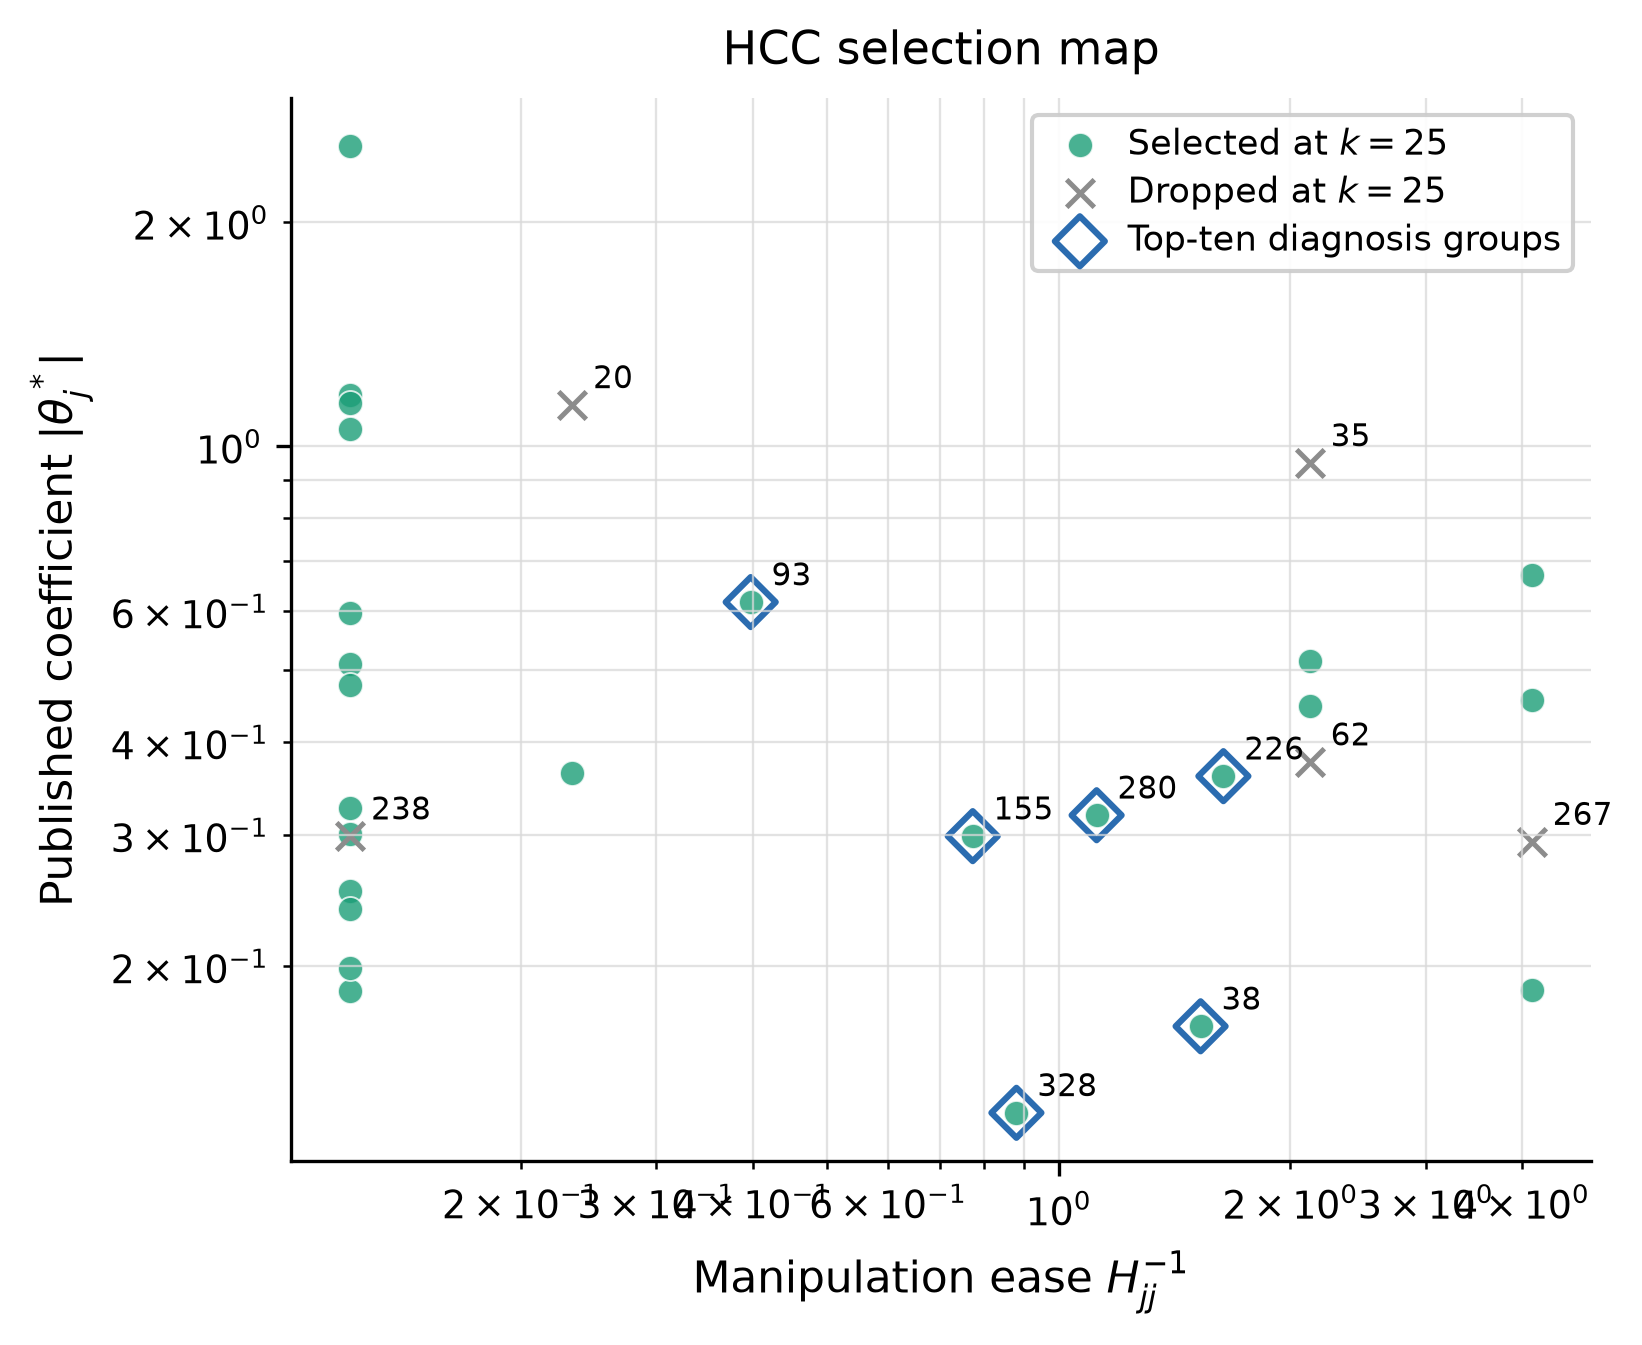

In [6]:
from IPython.display import Image, display

img_path = 'outputs/supp_signal_vs_manipulability_outputs/figures/supp_signal_vs_manipulability.png'
display(Image(filename=img_path))